In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence \
 import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
 summarize,
 poly)

In [7]:
rng = np.random.default_rng(10)
x1 = rng.uniform(0, 1, size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)

The equation is y = 2 + 2x1 + 0.3x2 where 2 and 0.3 are the regression coefficients for x1 and x2 respectively

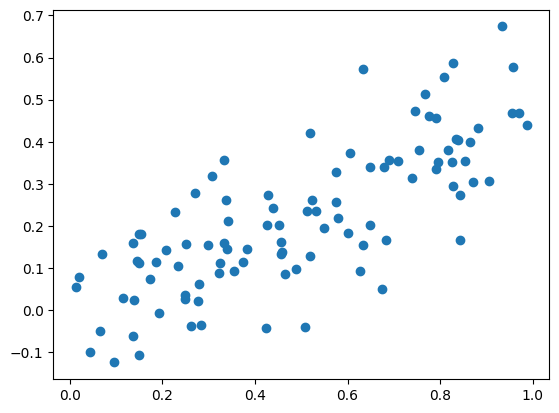

In [11]:
plt.scatter(x1, x2);

In [12]:
# Appears to be a positive linear relationship between x1 and x2

In [41]:
X = np.column_stack((x1, x2))
X = sm.add_constant(X)

In [42]:
model = sm.OLS(y, X)
results = model.fit()

In [43]:
summarize(results)

,coef,std err,t,P>|t|
const,2.0618,0.192,10.720,0.000
x1,0.8575,0.466,1.838,0.069
x2,2.2663,0.705,3.216,0.002


In [21]:
# The intercept is very close though the coefficients for the variables are off, and it seems like x2 cannot reject the null hypothesis

In [34]:
X = x1
X = sm.add_constant(X)

In [35]:
model = sm.OLS(y, X)
results = model.fit()

In [36]:
summarize(results)

,coef,std err,t,P>|t|
const,2.0739,0.201,10.310,0.0
x1,1.8760,0.358,5.236,0.0


In [25]:
# Now you can confidently reject null hypothesis

In [38]:
X = x2
X = sm.add_constant(X)

In [39]:
model = sm.OLS(y, X)
results = model.fit()

In [40]:
summarize(results)

,coef,std err,t,P>|t|
const,2.2840,0.151,15.088,0.0
x1,3.1458,0.524,6.008,0.0


In [32]:
# You can also reject null, but why is the coefficient 3??

The results do seem a bit contradictory, plotting x1 alone with y gives a much more accurate result than any other of the models. I think the issue lies with x2 directly correlating with x1

In [33]:
x1 = np.concatenate([x1, [0.1]])
x2 = np.concatenate([x2, [0.8]])
y = np.concatenate([y, [6]])

In [37]:
# The summaries above use the models with errors